# Entrega 2 Proyecto - Jefferson Andres Lipez Pinzon


## Imports

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,GlobalAveragePooling2D,Dropout, Flatten, Dense, Input
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

In [ ]:
import os
from google.colab import userdata

os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')


## Cargando el Dataset

In [ ]:
# Crea un directorio para el dataset
!mkdir -p facial-age-data

# Cambia al directorio para descargar el dataset allí
%cd facial-age-data

# Descarga el dataset de Kaggle
!kaggle datasets download -d frabbisw/facial-age

# Descomprime el archivo
!unzip facial-age.zip

# Vuelve al directorio raíz de Colab
%cd /content


/content/facial-age-data
Dataset URL: https://www.kaggle.com/datasets/frabbisw/facial-age
License(s): unknown
facial-age.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  facial-age.zip
replace face_age/001/1000.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace face_age/001/1018.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
replace face_age/001/1030.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace face_age/001/1062.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: no
replace face_age/001/1068.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: /content


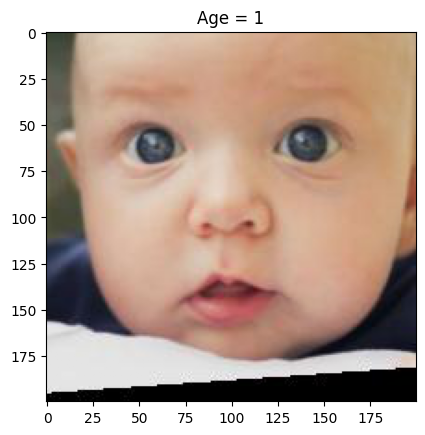

In [ ]:
path = '/content/facial-age-data/face_age/face_age/'

#Ejemplo
img = mpimg.imread(path+'001/16.png')
plt.imshow(img)
plt.title('Age = 1')
plt.show()

## Obteniendo los datos de entrenamiento, validación y testeo

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Creamos un DataFrame con las rutas de los archivos y sus respectivas edades (etiquetas)
file_paths = []
ages = []

for folder, _, files in os.walk(path):
    if folder != "face_age":
        for file in files:
            file_paths.append(os.path.join(folder, file))
            ages.append(str(folder[-3:]))  # Mantener como string o float según el generador

df_dataset = pd.DataFrame({
    'filepath': file_paths,
    'age': pd.to_numeric(ages)
})

# Split de los datos: 70% entrenamiento, 15% validación, 15% prueba
train_df, temp_df = train_test_split(df_dataset, test_size=0.3, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

# 2. Configurar el Generador de Datos (solo normalización)
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=True
)

val_generator = datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='age',
    target_size=(224, 224),
    class_mode='raw',
    batch_size=32,
    shuffle=False
)

Found 6844 validated image filenames.
Found 1467 validated image filenames.
Found 1467 validated image filenames.


### Creación del modelo



In [ ]:
import keras
from keras.layers import Add, Activation, BatchNormalization

def residual_block(input_tensor, filters, kernel_size=3):
    x = Conv2D(filters, kernel_size, padding='same')(input_tensor)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)

    x = Conv2D(filters, kernel_size, padding='same')(x)
    x = BatchNormalization()(x)

    shortcut = Conv2D(filters, (1, 1), padding='same')(input_tensor)
    shortcut = BatchNormalization()(shortcut)

    x = Add()([x, shortcut])
    x = Activation('relu')(x)
    return x

def build_resnet_age_model(input_shape=(224, 224, 3)):
    inputs = Input(shape=input_shape)


    x = Conv2D(32, (3, 3), padding='same', activation='relu')(inputs)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 64)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 128)
    x = MaxPooling2D((2, 2))(x)

    x = residual_block(x, 256)
    x = GlobalAveragePooling2D()(x)

    x = Dense(128, activation='relu')(x)
    x = Dropout(0.4)(x)
    outputs = Dense(1, activation='linear')(x)

    model = keras.models.Model(inputs, outputs)
    return model

model = build_resnet_age_model()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      2,112 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 112, 112,  │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │    147,584 │ activation_2[0][

 Total params: 1,244,865 (4.75 MB)

 Trainable params: 1,242,177 (4.74 MB)

 Non-trainable params: 2,688 (10.50 KB)

## Compilación y Entrenamiento del Modelo

In [ ]:
checkpointer = ModelCheckpoint(
    'modelface.keras',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

lr_reducer = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=[checkpointer, lr_reducer]
)

Epoch 1/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - loss: 49.7911 - mean_absolute_error: 5.0587
Epoch 1: val_loss improved from None to 116.69433, saving model to modelface.keras

Epoch 1: finished saving model to modelface.keras
214/214 ━━━━━━━━━━━━━━━━━━━━ 56s 207ms/step - loss: 50.0244 - mean_absolute_error: 5.0704 - val_loss: 116.6943 - val_mean_absolute_error: 7.5078 - learning_rate: 0.0010
Epoch 2/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - loss: 45.3908 - mean_absolute_error: 4.8250
Epoch 2: val_loss did not improve from 116.69433
214/214 ━━━━━━━━━━━━━━━━━━━━ 36s 168ms/step - loss: 48.0361 - mean_absolute_error: 4.9600 - val_loss: 302.1552 - val_mean_absolute_error: 13.9140 - learning_rate: 0.0010
Epoch 3/50
214/214 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - loss: 45.4767 - mean_absolute_error: 4.8459
Epoch 3: val_loss did not improve from 116.69433
214/214 ━━━━━━━━━━━━━━━━━━━━ 36s 168ms/step - loss: 45.5219 - mean_absolute_error: 4.8384 - val_loss: 118.8019 - val_mean_absolut

### Visualización del Historial de Entrenamiento

Graficaremos la evolución de la pérdida (MSE) y del error absoluto medio (MAE) para analizar el comportamiento y la convergencia del modelo.

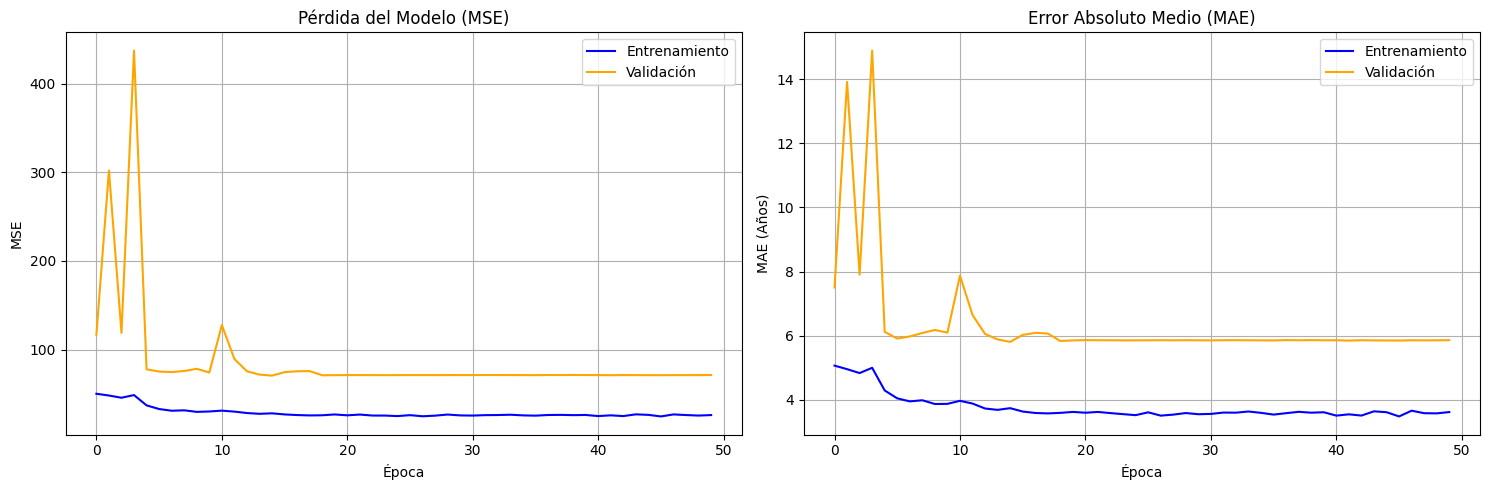

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Gráfico de Pérdida (MSE)
ax1.plot(history.history['loss'], label='Entrenamiento', color='blue')
ax1.plot(history.history['val_loss'], label='Validación', color='orange')
ax1.set_title('Pérdida del Modelo (MSE)')
ax1.set_xlabel('Época')
ax1.set_ylabel('MSE')
ax1.legend()
ax1.grid(True)

# Gráfico de MAE (Error Medio Absoluto)
ax2.plot(history.history['mean_absolute_error'], label='Entrenamiento', color='blue')
ax2.plot(history.history['val_mean_absolute_error'], label='Validación', color='orange')
ax2.set_title('Error Absoluto Medio (MAE)')
ax2.set_xlabel('Época')
ax2.set_ylabel('MAE (Años)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### Evaluación con el Conjunto de Prueba
Evaluamos el modelo final con datos totalmente nuevos para calcular el error definitivo de predicción.

In [ ]:
# Evaluamos el modelo final con el test_generator
test_loss, test_mae = model.evaluate(test_generator)
print(f"Pérdida (MSE) en Test: {test_loss:.4f}")
print(f"Error Absoluto Medio (MAE) en Test: {round(test_mae, 1)} años")

46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - loss: 82.8781 - mean_absolute_error: 5.8617
Pérdida (MSE) en Test: 82.8781
Error Absoluto Medio (MAE) en Test: 5.9 años


### Visualización de Predicciones de Ejemplo

Tomaremos un pequeño grupo de imágenes del conjunto de prueba para comparar visualmente la edad real de la persona frente a la edad estimada por nuestro modelo residual.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


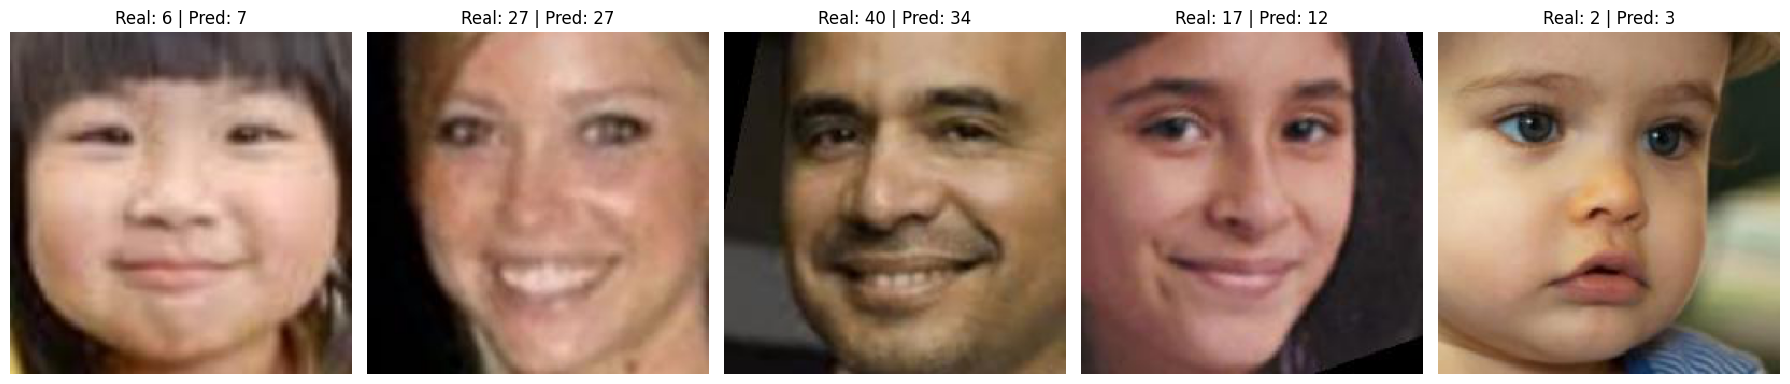

In [ ]:
# Obtener un lote de imágenes y etiquetas del generador de pruebas
x_test_batch, y_test_batch = next(test_generator)

# Realizar las predicciones con el modelo
predictions = model.predict(x_test_batch)

# Configurar la visualización de 5 ejemplos redondeando las predicciones
plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test_batch[i])
    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(predictions[i][0])))

    plt.title(f"Real: {real_age} | Pred: {predicted_age}")
    plt.axis('off')

plt.tight_layout()
plt.show()

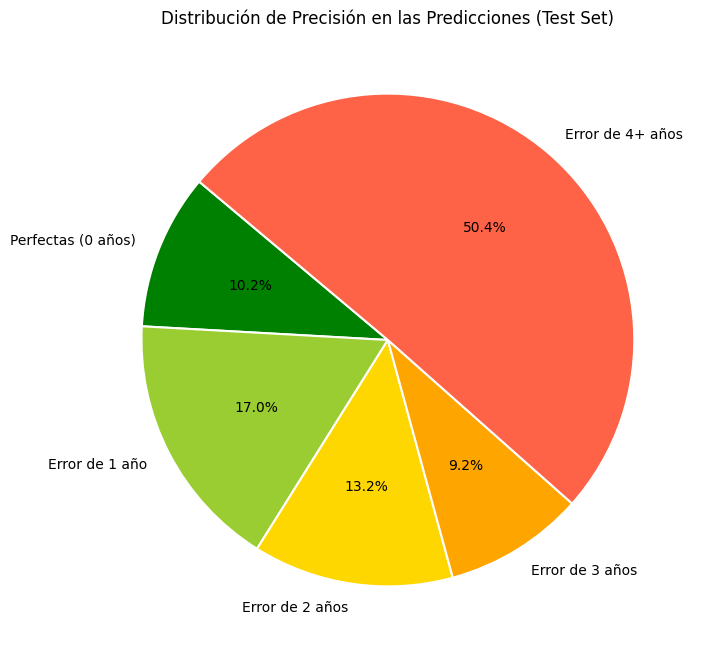

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener todas las predicciones y etiquetas reales del generador de pruebas
test_generator.reset()
all_preds = []
all_real = []

# Iterar sobre todo el generador para asegurar que cubrimos todos los datos de test
for _ in range(len(test_generator)):
    x_batch, y_batch = next(test_generator)
    preds = model.predict(x_batch, verbose=0)
    all_preds.extend(preds.flatten())
    all_real.extend(y_batch)

all_preds = np.array(all_preds)
all_real = np.array(all_real)

# 2. Redondear predicciones al entero más cercano y calcular error absoluto
rounded_preds = np.round(all_preds)
diferencias = np.abs(all_real - rounded_preds)

# 3. Clasificar los errores en categorías detalladas
perfectas = np.sum(diferencias == 0)
error_1_ano = np.sum(diferencias == 1)
error_2_anos = np.sum(diferencias == 2)
error_3_anos = np.sum(diferencias == 3)
resto = np.sum(diferencias >= 4)

total = len(diferencias)

# 4. Configurar datos del gráfico de pastel
etiquetas = [
    'Perfectas (0 años)',
    'Error de 1 año',
    'Error de 2 años',
    'Error de 3 años',
    'Error de 4+ años'
]
cantidades = [perfectas, error_1_ano, error_2_anos, error_3_anos, resto]
colores = ['green', 'yellowgreen', 'gold', 'orange', 'tomato']

# 5. Dibujar la gráfica
plt.figure(figsize=(8, 8))
plt.pie(
    cantidades,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribución de Precisión en las Predicciones (Test Set)')
plt.show()

### Visualización de Atención del Modelo con Grad-CAM

Dado que el modelo es una red convolucional residual (ResNet), podemos usar **Grad-CAM** para obtener un mapa de calor sobre las zonas del rostro que más influyeron en la predicción de la edad.

Usando la última capa convolucional encontrada: conv2d_9


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


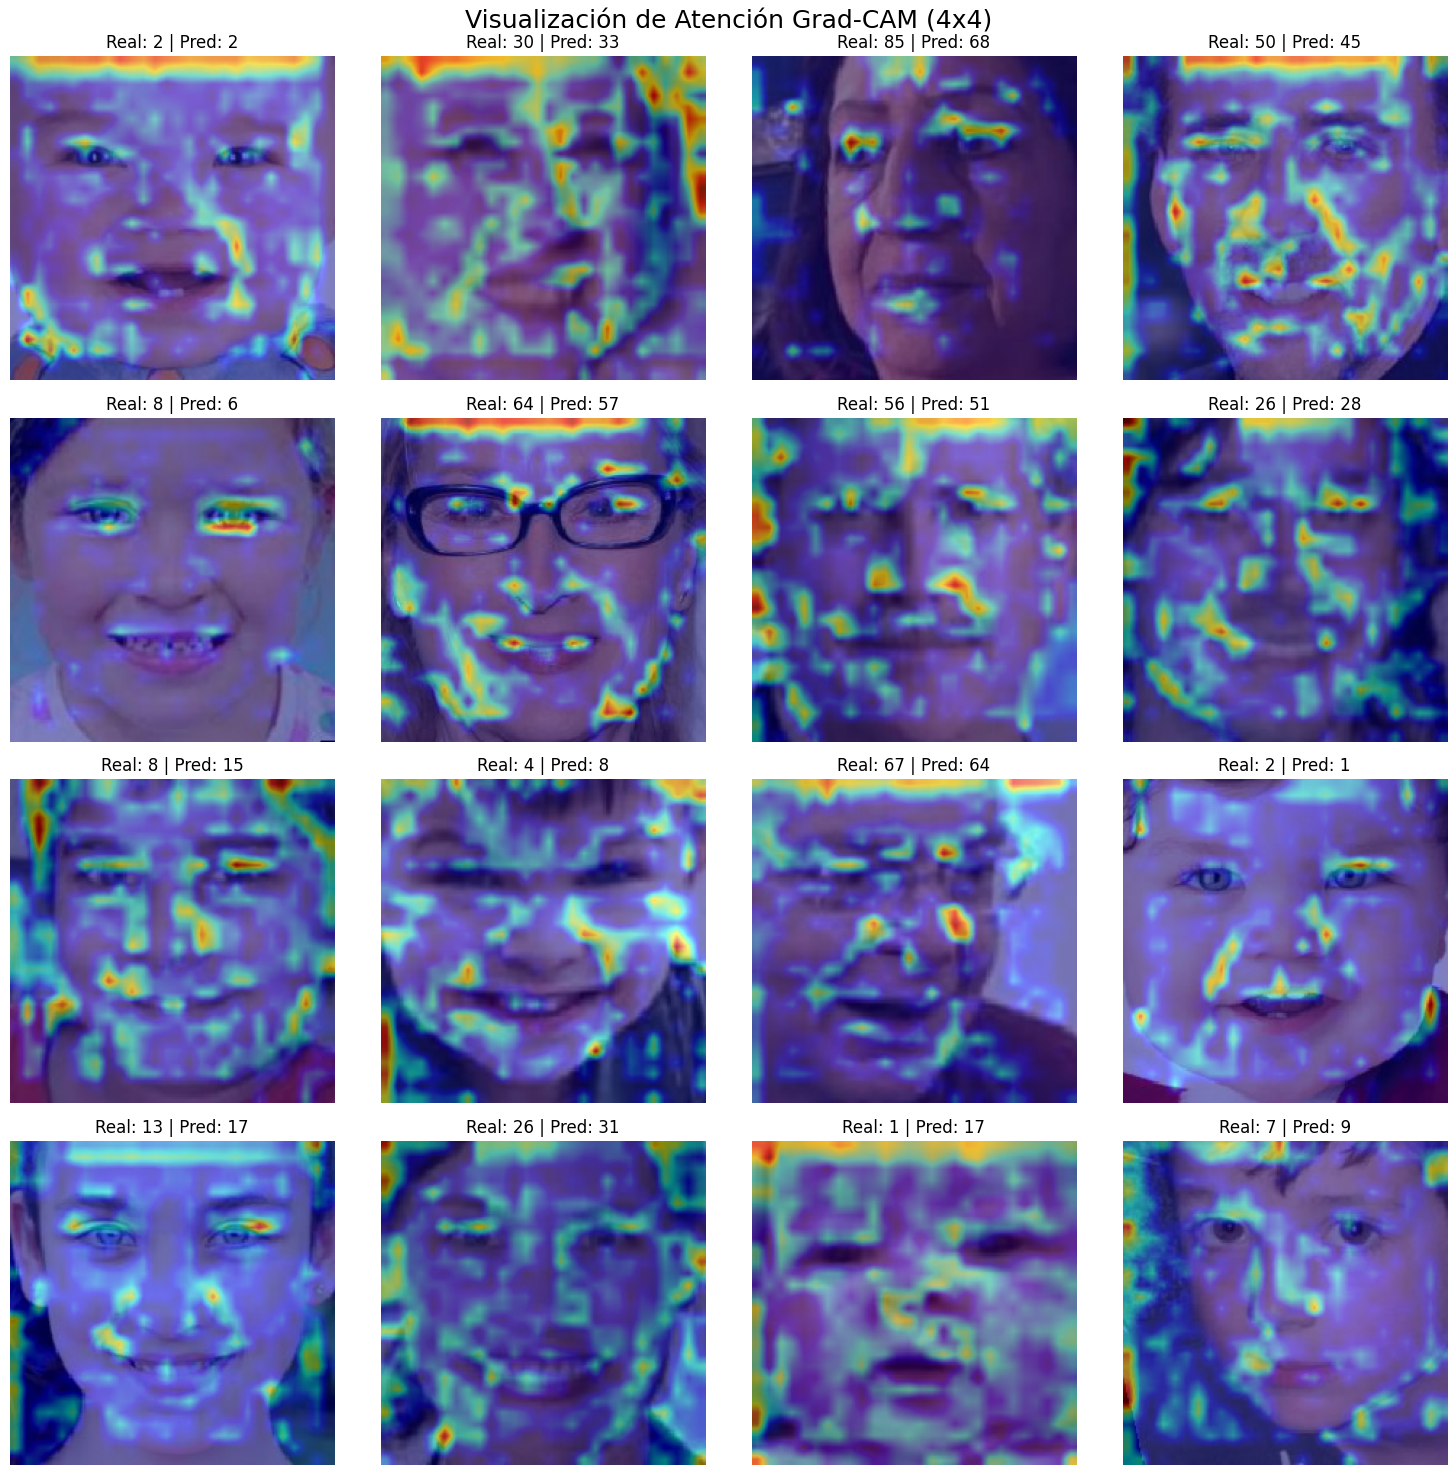

In [ ]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Crear un modelo que mapee la imagen de entrada a las activaciones de la última capa convolucional
    # y a la salida de predicción del modelo
    grad_model = tf.keras.models.Model(
        inputs=[model.inputs],
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcular el gradiente de la predicción respecto a los mapas de características de la última capa conv
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            score = preds[:, 0]
        else:
            score = preds[:, pred_index]

    # Gradiente del valor de salida respecto al mapa de características
    grads = tape.gradient(score, last_conv_layer_output)

    # Reducir los gradientes a un vector de pesos por canal
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplicar cada canal en el mapa de características por su "importancia"
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normalizar el mapa de calor entre 0 y 1 para su visualización
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def superimpose_heatmap(img, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    # Reescalar el mapa de calor al tamaño de la imagen original
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, colormap)

    # Convertir de BGR (OpenCV) a RGB
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Superponer el mapa de calor sobre la imagen original
    superimposed_img = heatmap * alpha + img * (1 - alpha)
    # Normalizar para mostrar correctamente con plt.imshow
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    return superimposed_img

# Encontrar el nombre de la última capa convolucional de la arquitectura
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"Usando la última capa convolucional encontrada: {last_conv_layer_name}")

# Resetear e iterar el generador de pruebas para obtener suficientes imágenes
test_generator.reset()
x_test_batch, y_test_batch = next(test_generator)

# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes con la atención Grad-CAM
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    img_input = np.expand_dims(img, axis=0)

    # Generar mapa de calor
    heatmap = make_gradcam_heatmap(img_input, model, last_conv_layer_name)

    # Convertir imagen normalizada (0-1) a rango 0-255 para OpenCV
    img_255 = np.uint8(img * 255)
    gradcam_img = superimpose_heatmap(img_255, heatmap, alpha=0.5)

    real_age = int(y_test_batch[i])
    predicted_age = int(round(float(model.predict(img_input, verbose=0)[0][0])))

    # Dibujar en una cuadrícula de 4x4 sólo la visualización Grad-CAM
    plt.subplot(4, 4, i + 1)
    plt.imshow(gradcam_img)
    plt.title(f"Real: {real_age} | Pred: {predicted_age}", fontsize=12)
    plt.axis('off')

plt.suptitle("Visualización de Atención Grad-CAM (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

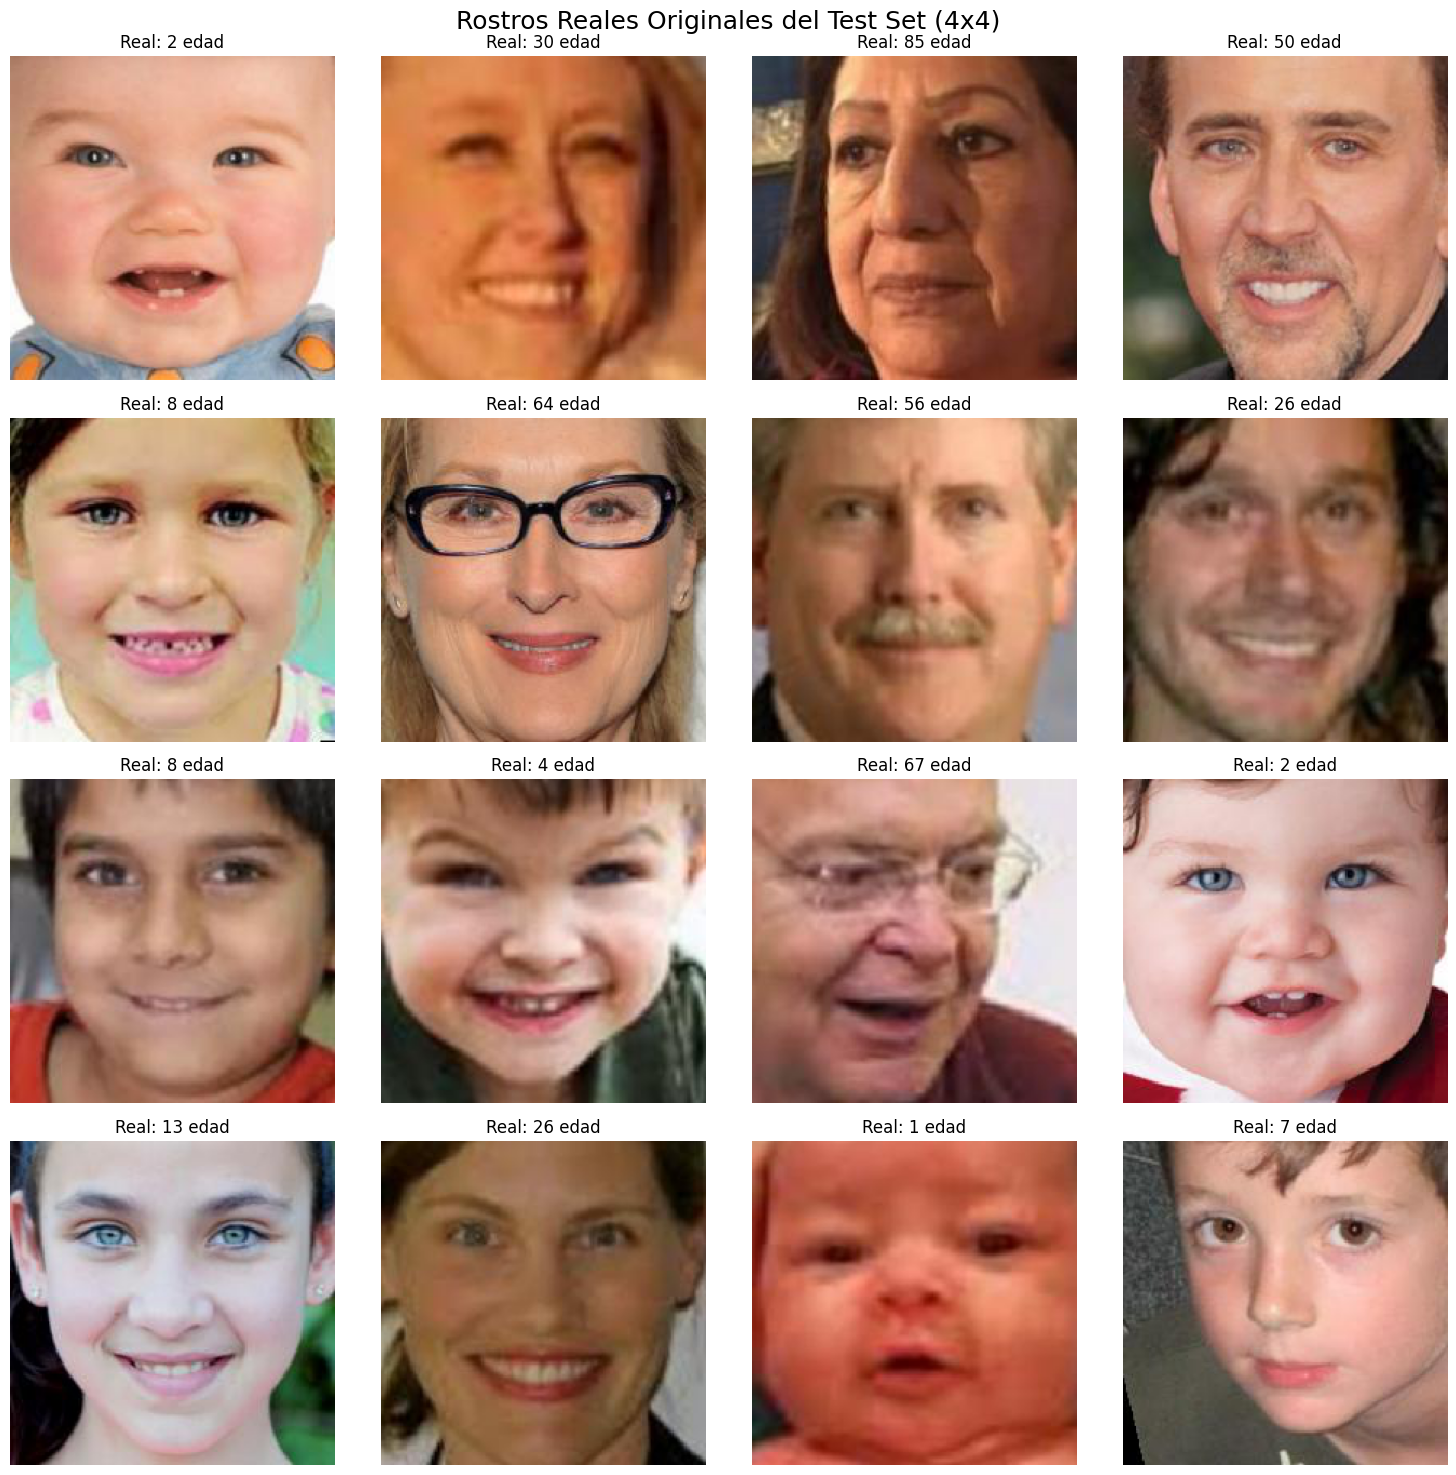

In [ ]:
# Graficar una grid de 4x4 que muestre únicamente las 16 imágenes reales originales
plt.figure(figsize=(15, 15))
for i in range(16):
    img = x_test_batch[i]
    real_age = int(y_test_batch[i])

    # Dibujar la cara real original sin mapas de calor
    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Real: {real_age} edad", fontsize=12)
    plt.axis('off')

plt.suptitle("Rostros Reales Originales del Test Set (4x4)", fontsize=18, y=0.98)
plt.tight_layout()
plt.show()

## Celdas extra (No las eliminé por si acaso pero no se usan)

In [ ]:
X=[]
Y=[]
for folder,_,files in os.walk(path):
    if folder!="face_age":
        for file in files:
            # Cargando Imagenes
            image = Image.open(folder +"/"+ file)
            image = image.convert('RGB')
            image = image.resize((224, 224))
            X.append(np.array(image))
            # Obteniendo la edad real
            Y.append(int(folder[-3:]))

X = np.array(X)
Y = np.array(Y)
# Normalizacion
X = X.astype('float32')
X /= 255.0
print(X[0],Y[0])

[[[0.6509804  0.54509807 0.47843137]
  [0.6313726  0.5254902  0.45882353]
  [0.5882353  0.48235294 0.41568628]
  ...
  [0.61960787 0.5058824  0.4509804 ]
  [0.5294118  0.40392157 0.3529412 ]
  [0.5254902  0.39215687 0.3529412 ]]

 [[0.69411767 0.5882353  0.52156866]
  [0.65882355 0.5529412  0.4862745 ]
  [0.6        0.49411765 0.42745098]
  ...
  [0.59607846 0.48235294 0.42745098]
  [0.5058824  0.38039216 0.3372549 ]
  [0.49803922 0.3647059  0.3254902 ]]

 [[0.6627451  0.5568628  0.49019608]
  [0.6901961  0.58431375 0.5176471 ]
  [0.68235296 0.5764706  0.50980395]
  ...
  [0.5372549  0.42745098 0.37254903]
  [0.44313726 0.31764707 0.27450982]
  [0.43137255 0.30588236 0.2627451 ]]

 ...

 [[0.627451   0.4627451  0.4       ]
  [0.56078434 0.40784314 0.34117648]
  [0.53333336 0.38039216 0.3137255 ]
  ...
  [0.8509804  0.84705883 0.827451  ]
  [0.8392157  0.8352941  0.8156863 ]
  [0.83137256 0.827451   0.8117647 ]]

 [[0.6313726  0.46666667 0.40392157]
  [0.56078434 0.40784314 0.34117648]


In [ ]:

X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42,shuffle=True)
print(len(X_train),len(Y_test))

7822 1956


Age =  75


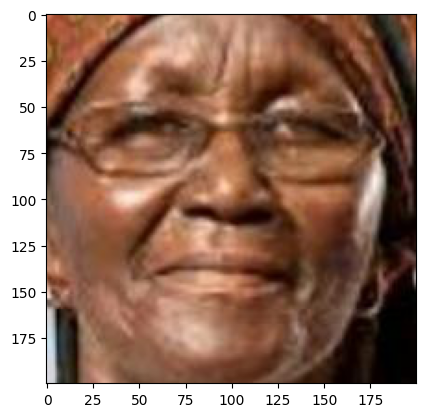

In [ ]:
plt.imshow(X_train[300])
print('Age = ',Y_train[300])

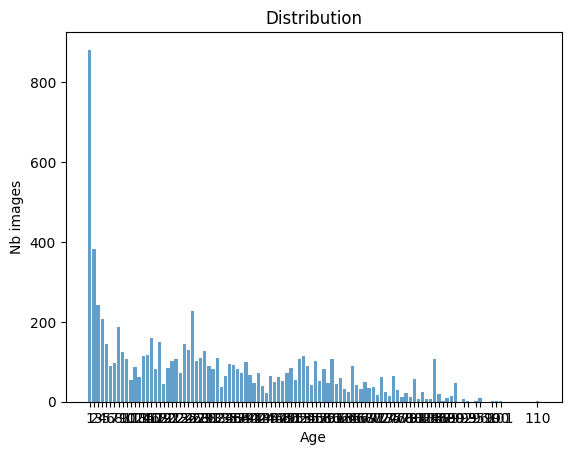

In [ ]:
unique, counts = np.unique(Y_train, return_counts=True)
plt.bar(unique, counts, align='center', alpha=0.7)
plt.xticks(unique, [str(i) for i in unique])
plt.xlabel('Age')
plt.ylabel('Nb images')
plt.title('Distribution')
plt.show()